In [1]:
import sys
import pandas as pd

print(sys.executable)
print("pandas version:", pd.__version__)

/Users/farzanadolatshahi/Documents/University/3rd Semester/Business Intelligence/Assignments/telco-customer-churn/.venv/bin/python
pandas version: 3.1.1


In [2]:
import pandas as pd 
from pathlib import Path

print (Path.cwd())

/Users/farzanadolatshahi/Documents/University/3rd Semester/Business Intelligence/Assignments/telco-customer-churn/notebooks


In [3]:
data_path = Path ("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(data_path)
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

In [5]:
print("Missing values per column:")
print(df.isna().sum())

blank_total_charges = df["TotalCharges"].str.strip().eq("")

print("\nBlank TotalCharges values:", blank_total_charges.sum())

df.loc[
    blank_total_charges,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [6]:
numeric_total_charges = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing after conversion:", numeric_total_charges.isna().sum())
print(
    "Missing values match the known blanks:",
    numeric_total_charges.isna().equals(blank_total_charges)
)

Missing after conversion: 11
Missing values match the known blanks: True


In [7]:
df_clean = df.copy()
df_clean["TotalCharges"] = numeric_total_charges
df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("TotalCharges type:", df_clean["TotalCharges"].dtype)
print("Remaining missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

Original shape: (7043, 21)
Cleaned shape: (7032, 21)
TotalCharges type: float64
Remaining missing TotalCharges: 0


In [8]:
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())
print("Duplicate full rows:", df_clean.duplicated().sum())

Duplicate customer IDs: 0
Duplicate full rows: 0


In [9]:
categorical_columns = df_clean.select_dtypes(include=["str", "object"]).columns

for column in categorical_columns:
    if column != "customerID":
        print(f"{column}: {df_clean[column].unique()}")

print("SeniorCitizen:", df_clean["SeniorCitizen"].unique())

gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup: <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract: <StringArray>
['Month-to-month', 'One year', '

In [10]:
churn_counts = df_clean["Churn"].value_counts()
churn_percentages = df_clean["Churn"].value_counts(normalize=True) * 100

print("Customer counts:")
print(churn_counts)

print("\nPercentages:")
print(churn_percentages.round(2))

Customer counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Percentages:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


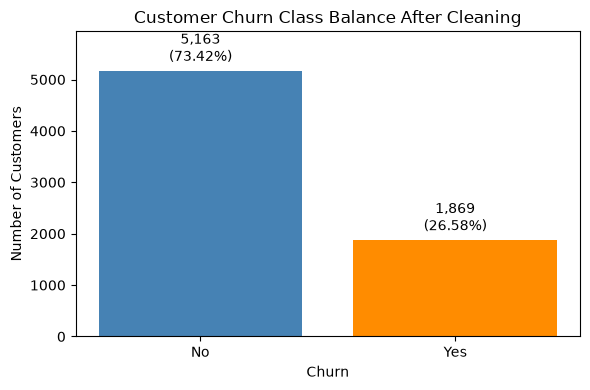

In [13]:
import matplotlib.pyplot as plt

churn_counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(churn_counts.index, churn_counts.values, color=["steelblue", "darkorange"])

ax.set_title("Customer Churn Class Balance After Cleaning")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

labels = [
    f"{count:,}\n({count / churn_counts.sum():.2%})"
    for count in churn_counts
]

ax.bar_label(ax.containers[0], labels=labels, padding=4)
ax.set_ylim(0, churn_counts.max() * 1.15)

fig.tight_layout()
fig.savefig("../figures/churn_class_balance.png", dpi=300, bbox_inches="tight")
plt.show()